# Интеграция пользовательского распознавателя в пайплайн

Пример для Manuscript OCR 0.1.13 на модели [taiga75/ru-trocr-1700s](https://huggingface.co/taiga75/ru-trocr-1700s).

Подключим распознаватель через собственный класс: он принимает страницу с разметкой и возвращает её с распознанным текстом. Такой подход подходит и для других моделей, которые хочется запускать своим кодом.

В Manuscript уже есть класс `TrOCR`. Здесь используем Transformers, чтобы показать устройство пользовательского адаптера. В конце приведён вариант с готовым классом и ONNX-экспортом.

## 1. Установка


In [1]:
%pip install "manuscript-ocr==0.1.13" "transformers==5.5.0" torch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 1.4 MB/s eta 0:00:001.4 MB/s eta 0:00:01m
  Attempting uninstall: transformers
    Found existing installation: transformers 5.1.0
    Uninstalling transformers-5.1.0:
      Successfully uninstalled transformers-5.1.0

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Пользовательский распознаватель

Пайплайн вызывает метод `predict(page, image)` и ожидает `Page` в ответ. Наследоваться от базового класса необязательно.

Наш адаптер выбирает текстовые области уровня `line`, вырезает их по прямоугольным границам и передаёт модели пакетами. Текст записывается в соответствующие элементы копии страницы; исходная разметка сохраняется.


In [2]:
from pathlib import Path

import torch
from PIL import Image
from IPython.display import display
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

from manuscript import Pipeline
from manuscript.data import TextRegion
from manuscript.detectors import EAST
from manuscript.layouts import SimpleSorting
from manuscript.utils.io import read_image
from manuscript.utils.geometry import crop_axis_aligned
from manuscript.utils.visualization import visualize_page


class CustomTrOCR:
    """Адаптер модели: обязательный метод predict принимает и возвращает Page."""

    def __init__(self, model_name, device="cpu", batch_size=1):
        if batch_size < 1:
            raise ValueError("batch_size должен быть положительным")
        self.device = device
        self.batch_size = batch_size
        # Уровни выбирает сам адаптер: пайплайн не вырезает области за него.
        self.recognition_levels = ["line"]
        # Здесь загрузите свою модель и её средства подготовки изображений.
        self.processor = TrOCRProcessor.from_pretrained(model_name)
        self.model = VisionEncoderDecoderModel.from_pretrained(model_name).to(device).eval()

    def predict(self, page, image):
        # page — дерево разметки после предыдущих этапов; image — исходный снимок.
        # Возвращаем Page, а не словарь или строку. Копия сохраняет вход без изменений.
        result = page.clone()
        pixels = read_image(image)
        regions, crops = [], []
        # Обходим все вложенные элементы, сохраняя их родителей и порядок.
        for element in result.descendants:
            if not isinstance(element, TextRegion) or element.type not in self.recognition_levels:
                continue
            if element.polygon is None:
                continue
            # polygon задан в координатах исходного снимка. Здесь выбираем bbox-кроп.
            crop = crop_axis_aligned(pixels, element.polygon)
            if crop is not None:
                regions.append(element)
                crops.append(Image.fromarray(crop))

        # Замените этот участок своим инференсом: один результат на каждый кроп,
        # в том же порядке, чтобы текст попал в правильную область страницы.
        for start in range(0, len(crops), self.batch_size):
            batch = crops[start:start + self.batch_size]
            inputs = self.processor(images=batch, return_tensors="pt").pixel_values.to(self.device)
            with torch.inference_mode():
                tokens = self.model.generate(inputs)
            texts = self.processor.batch_decode(tokens, skip_special_tokens=True)
            for region, text in zip(regions[start:start + self.batch_size], texts):
                # Распознанный текст хранится в TextRegion.text.
                region.text = text.strip()
                # Этот адаптер не вычисляет достоверность распознавания.
                region.recognition_confidence = None
        return result


/Users/user/manuscript-ocr/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Модель и изображение

Используем полную страницу `example/images/full/img1.jpeg`.


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 480/480 [00:00<00:00, 10657.22it/s]


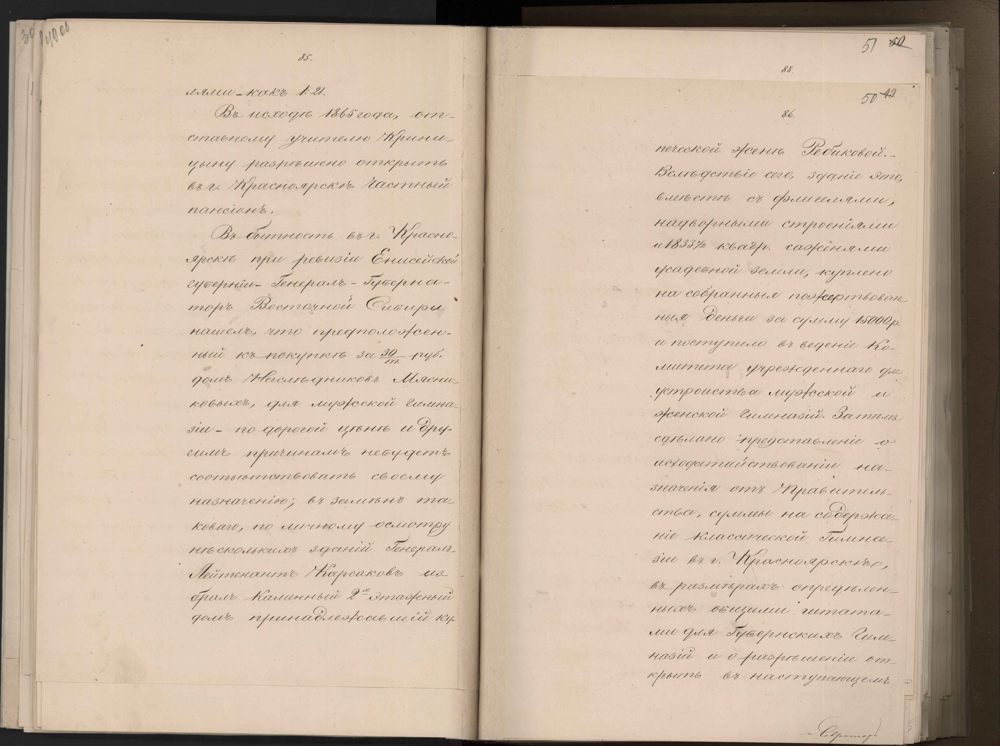

In [3]:
MODEL_NAME = "taiga75/ru-trocr-1700s"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 1

recognizer = CustomTrOCR(MODEL_NAME, device=DEVICE, batch_size=BATCH_SIZE)

PROJECT_DIR = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()),
    Path.cwd(),
)
image_path = PROJECT_DIR / "example/images/full/img1.jpeg"
if not image_path.exists():
    from urllib.request import urlretrieve
    image_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/"
        "4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images/img1.jpeg",
        image_path,
    )

image = Image.open(image_path).convert("RGB")
display(image)


## 4. Подключение к пайплайну

EAST находит слова, а `SimpleSorting` собирает их в строки. Именно эти строки получает наш распознаватель. Для детектора, который сразу возвращает строки, этот этап группировки не нужен.


цо

их оъ

85.
лями-какъ 1: 21.
Въ исходъ 1865 года, от-
стаѕному учителю Трини-
цыну разрѣшено открыть
вка. Трасноярскъ Ластный
пансинъ,
Вхбытность выг. Красно-
ярскi при ревизш Енисейфы
губернш- Генералъ- Губерна-
торъ Восточной Зивири
нашелъ, что префтоложен
ный къ покупнiъ За 30 руб.
домѣ Наслѣдниковъ Мясни
ковыхъ, для мужской Гимна-
3ш- по дорогой цѣнъ и дру-
еимъ причинамъ неѲцетъ
соотъютствовать своему
назначенiю; въ Зеимънѣ таї
коваго, по личному осмотру
нгъ сколькихъ ѕданiй Генералъ
Лейтенантъ Кареаковъ из-
бралъ Каменный 2 -Этажный
фольъ принадлежащiй кщ

51 52
88.
50 4
86.
печеской женъ Ребиковой.
Велгъфстьи сего, здание это,
вмѣсть съ флигелями,
надворными строенiями
и1833% кваѳр. саженями
Усадеѱной Земли, куплено
на собранныя пожертвован
ныя Деньги за сумму 1500020
и поступило въ веденi Ко-
мштета учрежденнаго фа
устроисть а мужской и
женской Гимнасiй. Затик
сдѣлано представленiе -
исюфитайствование на-
значенiя отъ Мгравитель
стьа, суммы на содержа
нiе Классической Гимна


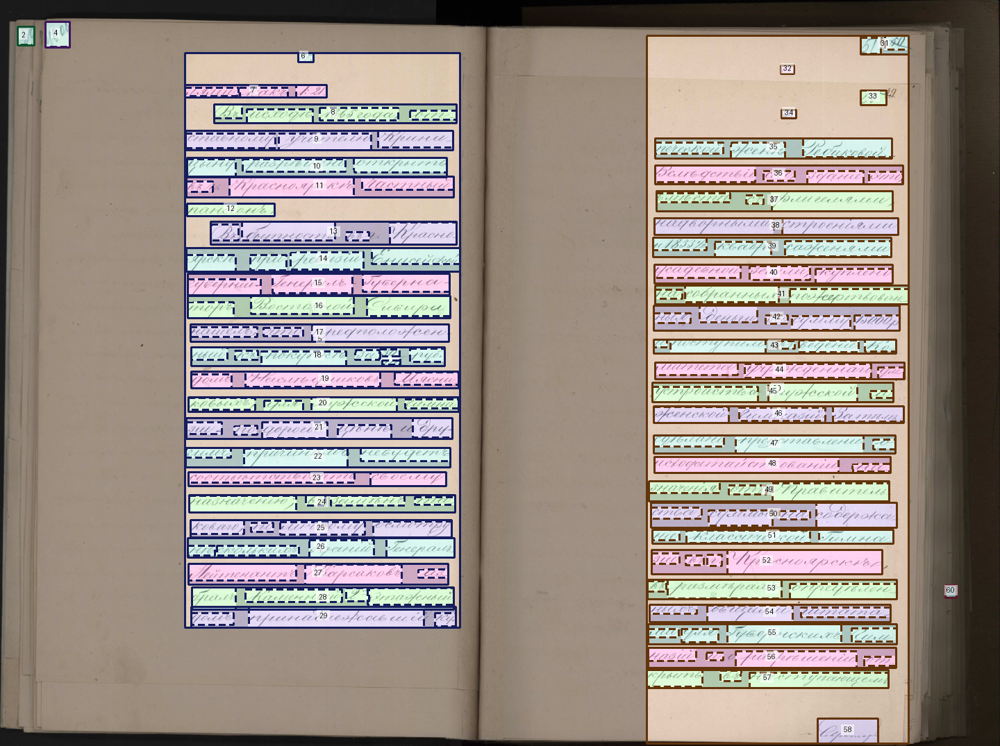

In [4]:
pipeline = Pipeline(
    detector=EAST(weights="east_50_g1", device="cpu"),
    layout=SimpleSorting(),
    recognizer=recognizer,  # Наш пользовательский адаптер TrOCR.
    corrector=None,
)
result = pipeline.predict(image)  # Пайплайн возвращает словарь результатов.
page = result["page"]

print(page.get_text())
display(visualize_page(image, page, max_size=1440, upscale=True))


## 5. Альтернатива: готовый TrOCR из Manuscript

Если собственная реализация не нужна, модель можно экспортировать скриптом [scripts/export_trocr.py](../../scripts/export_trocr.py) и подключить через `TrOCR`.

Сначала скачайте файлы модели в локальную папку:

```python
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="taiga75/ru-trocr-1700s",
    local_dir="models/ru-trocr-1700s/source",
)
```

Из корня репозитория запустите экспорт:

```bash
python scripts/export_trocr.py models/ru-trocr-1700s/source models/ru-trocr-1700s/onnx --no-fp16
```

Затем замените пользовательский адаптер готовым распознавателем:

```python
from manuscript.recognizers import TrOCR

recognizer = TrOCR(
    weights="models/ru-trocr-1700s/onnx/encoder.fp32.onnx",
    config="models/ru-trocr-1700s/onnx/encoder.fp32.json",
    device="cpu",
)
```

Конфиг содержит ссылки на декодеры и токенизатор. Для работы нужны все файлы экспортированной папки; одного энкодера недостаточно. Этот распознаватель передаётся в `Pipeline` тем же параметром `recognizer`.
